# Denoising real DAS data

Goal: the cleanest possible mask of moving vehicles on **real** data, using only techniques from Lab 1-4 (point operations, convolution/blurs, morphology, FFT).

Data: two 2-minute segments - **09:10:52-09:12:52** (files 091052-091242) and **09:12:22-09:14:22** (files 091222-091412).

Real data has no ground truth, so we made a small **hand-made reference** (`annotations/real_reference.json`):
- **points** - 60 points lying on about 30 vehicle lines (clear and faint ones), placed by eye and snapped to the local maximum,
- **quiet boxes** - 9 areas with no vehicle in any frequency band.

A mask is scored by:
- **hit** - share of points with a mask pixel within +-0.5 s (same channel); **hit 0.25 s** - the same with +-0.25 s,
- **false** - share of quiet-box pixels that are in the mask (false alarms),
- **density** - share of all pixels in the mask (lower = thinner lines),
- **speckle** - share of mask pixels in tiny blobs (< 30 pixels = 1.2 s x 1 channel) - noise left in the mask.

In [1]:
import glob
import json

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DX = 5.106500953873407   # m between channels
DT = 0.0016              # s between samples
STEP = 25                # downsampling in time: 25 samples -> 1 row
DT2 = DT * STEP          # 0.04 s per row


def load_real(first_file, last_file):
    files = sorted(f for f in glob.glob('real-world-data/*.npy') if first_file <= f[-10:-4] <= last_file)
    return np.concatenate([np.load(f) for f in files]).astype(np.float64)


reference = json.load(open('annotations/real_reference.json'))
segments = {name: load_real(*name.split('-')) for name in ['091052-091242', '091222-091412']}
print({name: x.shape for name, x in segments.items()})

{'091052-091242': (75000, 52), '091222-091412': (75000, 52)}


## 1. Basic operations

In [2]:
def band_pass(x, low, high):
    """Lab 4: FFT of every channel, zero outside [low, high] Hz, inverse FFT."""
    spectrum = np.fft.rfft(x, axis=0)
    freqs = np.fft.rfftfreq(len(x), DT)
    spectrum[(freqs < low) | (freqs > high)] = 0
    return np.fft.irfft(spectrum, n=len(x), axis=0)


def downsample(x):
    """Mean of every 25 samples (0.04 s)."""
    n = len(x) // STEP * STEP
    return x[:n].reshape(-1, STEP, x.shape[1]).mean(axis=1)


def envelope(x, low, high, gradient=False):
    """|band-passed signal| (optionally its time derivative, as in search.ipynb), averaged over 0.04 s."""
    y = band_pass(x, low, high)
    if gradient:
        y = np.gradient(y, axis=0)
    return downsample(np.abs(y))


def log_ratio(env):
    """Lab 1 point operation: log(value / median of its channel) - every channel gets the same scale."""
    return np.log(env / np.median(env, axis=0))


def remove_row_median(score):
    """Subtract the median of every row - removes short bursts that hit all channels at once (horizontal stripes)."""
    return score - np.median(score, axis=1, keepdims=True)


def hysteresis(score, low, high):
    """Lab 3: start from pixels > high and keep dilating (3x3) inside the pixels > low.
    Faint pixels survive only if they are connected to a strong part of a line."""
    seed = (score > high).astype(np.uint8)
    allowed = (score > low).astype(np.uint8)
    while True:
        grown = cv2.dilate(seed, np.ones((3, 3), np.uint8)) & allowed
        if np.array_equal(grown, seed):
            return seed.astype(bool)
        seed = grown


def fan_filter(score, min_kmh=10, max_kmh=130):
    """Lab 4: 2D FFT of the image; a line moving with speed v lies on f = v * k, so keep only |f / k| in [min, max]."""
    h, w = score.shape
    mean = score.mean()
    padded = np.concatenate([score - mean, (score - mean)[:, ::-1][:, :64 - w]], axis=1)   # mirror to 64 channels
    f = np.fft.fftfreq(h, DT2)[:, None]
    k = np.fft.fftfreq(64, DX)[None, :]
    speed = np.abs(f) / np.maximum(np.abs(k), 1e-12) * 3.6
    keep = (speed >= min_kmh) & (speed <= max_kmh)
    keep[0, 0] = True
    return np.real(np.fft.ifft2(np.fft.fft2(padded) * keep))[:, :w] + mean


def friend_chain(x, percentile=75, ratio=None):
    """Best chain from search.ipynb (band-pass 1-100 Hz, |gradient|, threshold, opening 5x1, closing 125x1)."""
    score = np.abs(np.gradient(band_pass(x, 1, 100), axis=0))
    if ratio is None:
        score = score - np.median(score, axis=0)
        mask = score > np.percentile(score, percentile)
    else:
        mask = score / np.median(score, axis=0) > ratio
    mask = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, np.ones((5, 1), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((125, 1), np.uint8))
    return downsample(mask.astype(np.float32)) > 0.5


def evaluate(mask, ref):
    hits = {}
    for tol in [0.5, 0.25]:
        r = int(tol / DT2)
        hits[tol] = np.mean([mask[max(int(round(t / DT2)) - r, 0):int(round(t / DT2)) + r + 1, c].any() for c, t in ref['points']])
    quiet = np.concatenate([mask[int(t0 / DT2):int(t1 / DT2), c0:c1 + 1].ravel() for c0, c1, t0, t1 in ref['quiet']])
    # speckle (evaluation only): pixels in connected blobs smaller than 30 pixels
    _, _, stats, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    areas = stats[1:, cv2.CC_STAT_AREA]
    return {'hit': hits[0.5], 'hit 0.25 s': hits[0.25], 'false': quiet.mean(), 'density': mask.mean(),
            'speckle': areas[areas < 30].sum() / max(mask.sum(), 1)}


def show(ax, image, title, **kwargs):
    if image.dtype == bool:
        kwargs = {'cmap': 'gray', **kwargs}
    else:
        kwargs = {'cmap': 'magma', 'vmin': 0, 'vmax': np.percentile(image, 99.5), **kwargs}
    ax.imshow(image, aspect='auto', interpolation='nearest', extent=[0, image.shape[1] * DX, len(image) * DT2, 0], **kwargs)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('space [m]')

## 2. Reference annotation

Red crosses = points on vehicles, green boxes = quiet areas. Background: maximum of the 0.5-5 Hz and 40-100 Hz envelopes (each scaled by its 99th percentile).

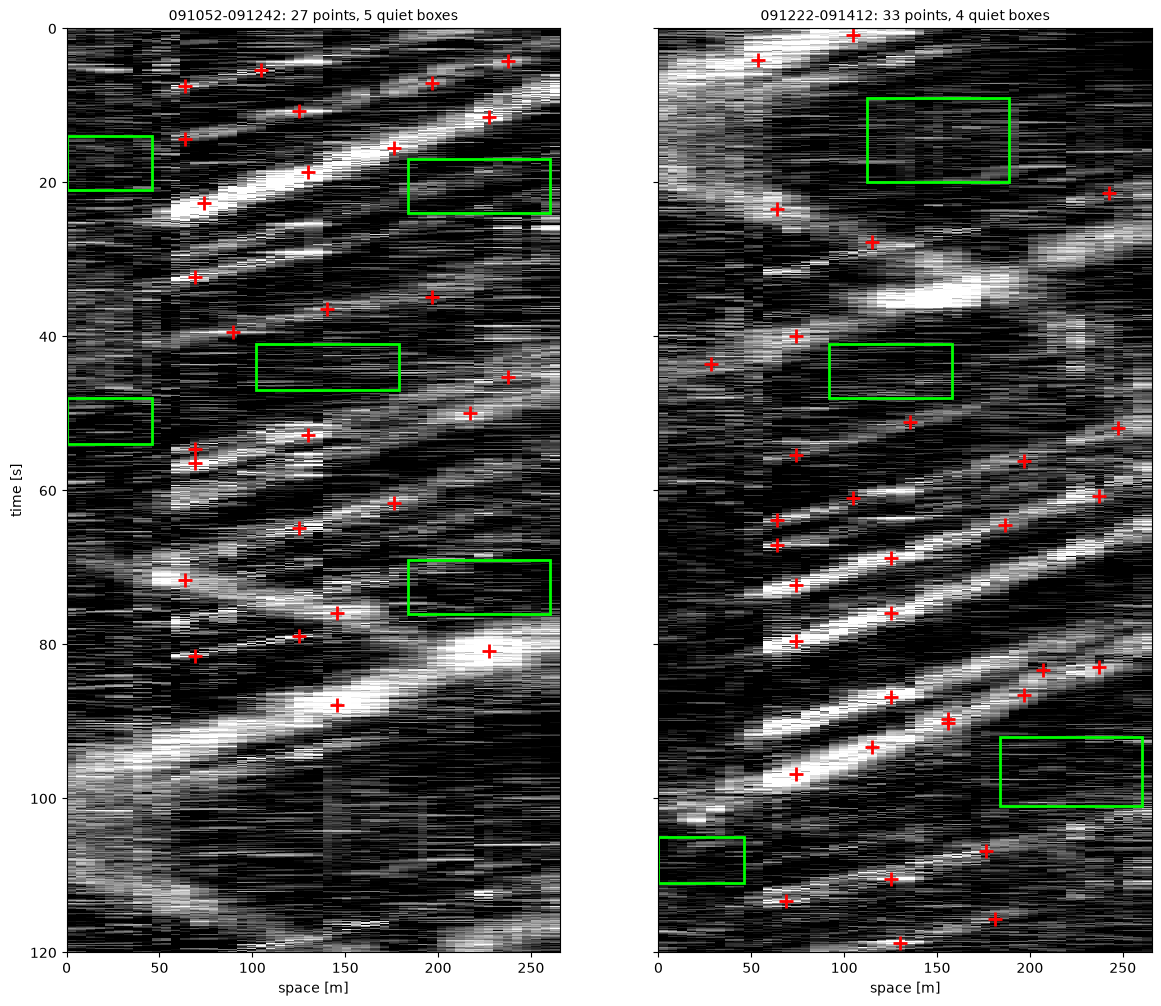

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 12), sharey=True)
for ax, (name, x) in zip(axes, segments.items()):
    parts = [np.clip(remove_row_median(log_ratio(envelope(x, lo, hi))), 0, None) for lo, hi in [(0.5, 5), (40, 100)]]
    background = np.maximum(*[p / np.percentile(p, 99) for p in parts])
    show(ax, background, f'{name}: {len(reference[name]["points"])} points, {len(reference[name]["quiet"])} quiet boxes', vmax=1, cmap='gray')
    points = np.array(reference[name]['points'])
    ax.plot((points[:, 0] + 0.5) * DX, points[:, 1], 'r+', ms=10, mew=2)
    for c0, c1, t0, t1 in reference[name]['quiet']:
        ax.add_patch(plt.Rectangle((c0 * DX, t0), (c1 - c0 + 1) * DX, t1 - t0, fill=False, ec='lime', lw=2))
axes[0].set_ylabel('time [s]')
plt.show()

## 3. Frequency analysis (per-channel FFT)

**Band images**: the envelope of each frequency band (log ratio to channel median, row median removed). Vehicles look different in every band.

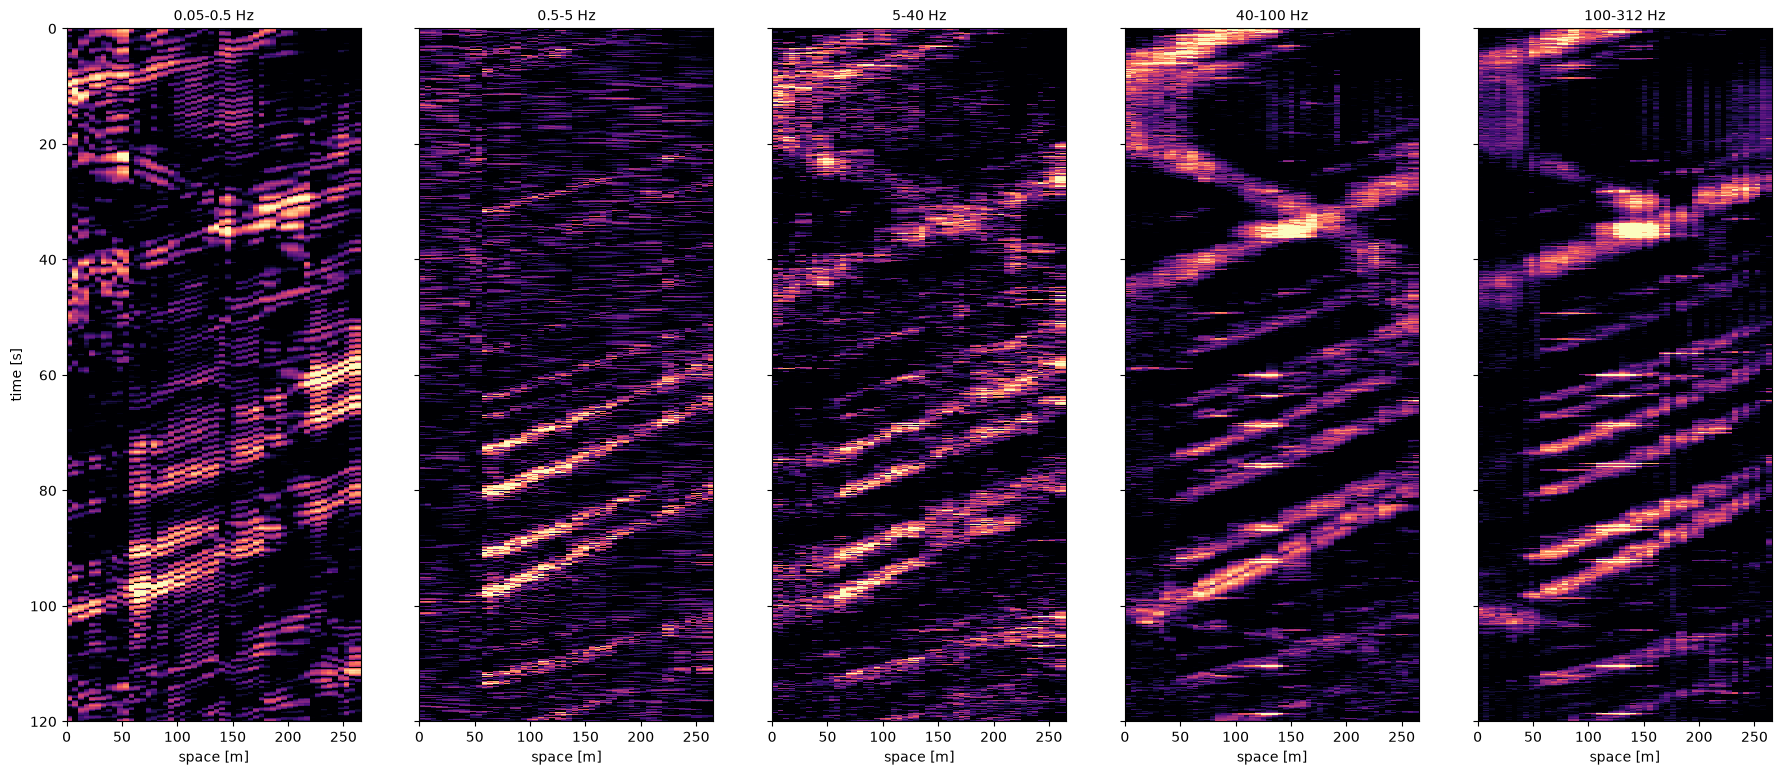

In [4]:
BANDS = [(0.05, 0.5), (0.5, 5), (5, 40), (40, 100), (100, 312)]
x = segments['091222-091412']
fig, axes = plt.subplots(1, len(BANDS), figsize=(22, 9), sharey=True)
for ax, (lo, hi) in zip(axes, BANDS):
    show(ax, remove_row_median(log_ratio(envelope(x, lo, hi))), f'{lo}-{hi} Hz')
axes[0].set_ylabel('time [s]')
plt.show()

**Vehicle vs quiet spectrum**: power spectrum of 1 s windows of single channels, centred on the reference points (vehicles) and inside the quiet boxes (background). The ratio says at which frequencies vehicles stand out from the background.

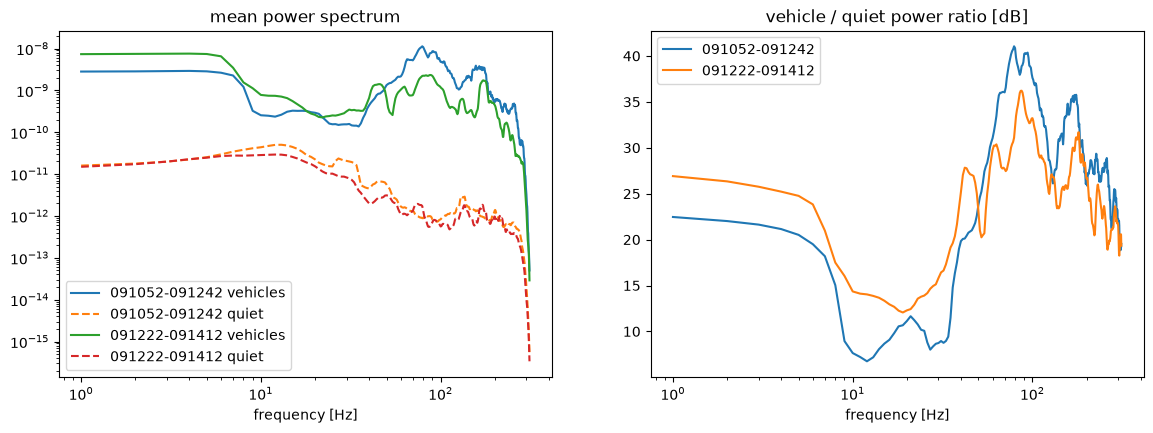

In [5]:
W = 625   # 1 s window
freqs = np.fft.rfftfreq(W, DT)
smooth = lambda p: np.convolve(p, np.ones(9) / 9, mode='same')
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for name, x in segments.items():
    vehicle, quiet = [], []
    for c, t in reference[name]['points']:
        r = int(t / DT) - W // 2
        if r >= 0 and r + W <= len(x):
            vehicle.append(np.abs(np.fft.rfft(x[r:r + W, c] * np.hanning(W))) ** 2)
    for c0, c1, t0, t1 in reference[name]['quiet']:
        for c in range(c0, c1 + 1):
            for r in range(int(t0 / DT), int(t1 / DT) - W, W):
                quiet.append(np.abs(np.fft.rfft(x[r:r + W, c] * np.hanning(W))) ** 2)
    vehicle, quiet = smooth(np.mean(vehicle, axis=0)), smooth(np.mean(quiet, axis=0))
    axes[0].loglog(freqs[1:], vehicle[1:], label=f'{name} vehicles')
    axes[0].loglog(freqs[1:], quiet[1:], '--', label=f'{name} quiet')
    axes[1].semilogx(freqs[1:], 10 * np.log10(vehicle / quiet)[1:], label=name)
axes[0].set_title('mean power spectrum')
axes[1].set_title('vehicle / quiet power ratio [dB]')
for ax in axes:
    ax.set_xlabel('frequency [Hz]')
    ax.legend()
plt.show()

- Vehicles stand out most at **40-200 Hz (35-40 dB)**; at 8-30 Hz the background is strongest and the ratio drops to ~10 dB.
- Below 5 Hz (the static load of the vehicle) the ratio is also high, but the band images show many horizontal stripes there and the first ~10 channels see almost nothing.
- The first ~10 channels (0-50 m) are much less sensitive in all bands - lines often start at ~50 m.

## 4. Search over chains

Every chain: **envelope of a band -> log ratio to channel median -> remove row median -> smoothing -> decision**.
- bands: 1-100 Hz |gradient| (as in `search.ipynb`), 5-100, 20-100, 40-100, 40-312 Hz,
- smoothing (Lab 2): none, median 5x5, Gaussian 5 rows (0.2 s) along time, Gaussian 3x3,
- decision: one threshold (2, 2.5, 3 x channel median) or hysteresis (Lab 3, low-high pairs).

Selection: chains with hit >= 0.96 on **both** segments and false <= 1.5 % are kept, then sorted by hit within 0.25 s (how well the mask lies on the line) and speckle.

In [6]:
SMOOTHING = {'none': lambda s: s,
             'median 5x5': lambda s: cv2.medianBlur(s, 5),
             'gauss 5 rows': lambda s: cv2.GaussianBlur(s, (1, 5), 0),
             'gauss 3x3': lambda s: cv2.GaussianBlur(s, (3, 3), 0)}
DECISIONS = {**{f'thr {t}': (lambda s, t=t: s > np.log(t)) for t in [2, 2.5, 3]},
             **{f'hyst {lo}-{hi}': (lambda s, lo=lo, hi=hi: hysteresis(s, np.log(lo), np.log(hi))) for lo, hi in [(1.5, 3), (1.75, 3.5), (2, 4)]}}
SEARCH_BANDS = {'1-100 grad': (1, 100, True), '5-100': (5, 100, False), '20-100': (20, 100, False),
                '40-100': (40, 100, False), '40-312': (40, 312, False)}

rows = []
for band_name, (lo, hi, grad) in SEARCH_BANDS.items():
    base = {name: remove_row_median(log_ratio(envelope(x, lo, hi, grad))).astype(np.float32) for name, x in segments.items()}
    for smooth_name, smooth_fn in SMOOTHING.items():
        scores = {name: smooth_fn(s) for name, s in base.items()}
        for decision_name, decide in DECISIONS.items():
            for name, s in scores.items():
                rows.append({'band': band_name, 'smoothing': smooth_name, 'decision': decision_name, 'segment': name,
                             **evaluate(decide(s), reference[name])})
search = pd.DataFrame(rows)
by_chain = search.groupby(['band', 'smoothing', 'decision']).agg(
    hit_min=('hit', 'min'), hit_025=('hit 0.25 s', 'mean'), false=('false', 'mean'),
    density=('density', 'mean'), speckle=('speckle', 'mean'))
good = by_chain[(by_chain['hit_min'] >= 0.96) & (by_chain['false'] <= 0.015)]
print(f'{len(by_chain)} chains, {len(good)} with full recall and few false alarms')
display(good.sort_values(['hit_025', 'speckle'], ascending=[False, True]).head(10).round(3))

120 chains, 13 with full recall and few false alarms


hit_min  hit_025  false  density  \
band       smoothing    decision                                          
40-312     gauss 5 rows hyst 1.75-3.5    0.963    0.981  0.007    0.242   
           gauss 3x3    hyst 1.75-3.5    0.963    0.966  0.004    0.238   
           none         hyst 1.75-3.5    0.963    0.966  0.014    0.242   
1-100 grad none         thr 2.5          1.000    0.951  0.010    0.175   
           gauss 3x3    hyst 1.5-3       0.963    0.948  0.012    0.282   
           none         hyst 2-4         0.963    0.948  0.007    0.208   
                        hyst 1.75-3.5    0.963    0.948  0.014    0.243   
40-312     median 5x5   thr 2            0.963    0.948  0.007    0.208   
           gauss 3x3    thr 2            0.963    0.948  0.011    0.218   
           gauss 5 rows thr 2            0.963    0.948  0.014    0.221   

                                       speckle  
band       smoothing    decision                
40-312     gauss 5 rows hyst 1.75-3.5    0.003  
           gauss 3x3    hyst 1.75-3.5    0.004  
           none         hyst 1.75-3.5    0.017  
1-100 grad none         thr 2.5          0.100  
           gauss 3x3    hyst 1.5-3       0.001  
           none         hyst 2-4         0.015  
                        hyst 1.75-3.5    0.017  
40-312     median 5x5   thr 2            0.022  
           gauss 3x3    thr 2            0.040  
           gauss 5 rows thr 2            0.042

## 5. Comparison of the main candidates

In [7]:
def score(x, low, high, gradient=False):
    return remove_row_median(log_ratio(envelope(x, low, high, gradient))).astype(np.float32)


def best_chain(x):
    """Chosen chain: 40-312 Hz envelope -> log ratio -> row median -> Gaussian 0.2 s along time -> hysteresis 1.75x / 3.5x."""
    s = cv2.GaussianBlur(score(x, 40, 312), (1, 5), 0)
    return hysteresis(s, np.log(1.75), np.log(3.5))


CANDIDATES = {
    'A: search.ipynb best (75th percentile)': lambda x: friend_chain(x),
    'B: search.ipynb chain, 4 x channel median': lambda x: friend_chain(x, ratio=4),
    'C: 1-100 Hz |grad| envelope, row median, 2.5x': lambda x: score(x, 1, 100, True) > np.log(2.5),
    'D: like C + fan filter 10-130 km/h, 2x': lambda x: fan_filter(score(x, 1, 100, True)) > np.log(2),
    'E: like C without row median': lambda x: log_ratio(envelope(x, 1, 100, True)) > np.log(2.5),
    'BEST: 40-312 Hz, row median, Gauss, hysteresis': best_chain,
}
masks = {(c, name): fn(x) for c, fn in CANDIDATES.items() for name, x in segments.items()}
table = pd.DataFrame({key: evaluate(m, reference[key[1]]) for key, m in masks.items()}).T
table.index.names = ['chain', 'segment']
display(table.round(3))

hit  \
chain                                          segment                
A: search.ipynb best (75th percentile)         091052-091242  0.926   
                                               091222-091412  0.939   
B: search.ipynb chain, 4 x channel median      091052-091242  0.815   
                                               091222-091412  0.758   
C: 1-100 Hz |grad| envelope, row median, 2.5x  091052-091242  1.000   
                                               091222-091412  1.000   
D: like C + fan filter 10-130 km/h, 2x         091052-091242  0.815   
                                               091222-091412  0.909   
E: like C without row median                   091052-091242  0.963   
                                               091222-091412  0.939   
BEST: 40-312 Hz, row median, Gauss, hysteresis 091052-091242  0.963   
                                               091222-091412  1.000   

                                                              hit 0.25 s  \
chain                                          segment                     
A: search.ipynb best (75th percentile)         091052-091242       0.889   
                                               091222-091412       0.909   
B: search.ipynb chain, 4 x channel median      091052-091242       0.815   
                                               091222-091412       0.727   
C: 1-100 Hz |grad| envelope, row median, 2.5x  091052-091242       0.963   
                                               091222-091412       0.939   
D: like C + fan filter 10-130 km/h, 2x         091052-091242       0.778   
                                               091222-091412       0.909   
E: like C without row median                   091052-091242       0.926   
                                               091222-091412       0.879   
BEST: 40-312 Hz, row median, Gauss, hysteresis 091052-091242       0.963   
                                               091222-091412       1.000   

                                                              false  density  \
chain                                          segment                         
A: search.ipynb best (75th percentile)         091052-091242  0.074    0.328   
                                               091222-091412  0.017    0.328   
B: search.ipynb chain, 4 x channel median      091052-091242  0.027    0.201   
                                               091222-091412  0.002    0.174   
C: 1-100 Hz |grad| envelope, row median, 2.5x  091052-091242  0.013    0.182   
                                               091222-091412  0.006    0.169   
D: like C + fan filter 10-130 km/h, 2x         091052-091242  0.011    0.220   
                                               091222-091412  0.001    0.190   
E: like C without row median                   091052-091242  0.036    0.229   
                                               091222-091412  0.005    0.203   
BEST: 40-312 Hz, row median, Gauss, hysteresis 091052-091242  0.006    0.241   
                                               091222-091412  0.008    0.243   

                                                              speckle  
chain                                          segment                 
A: search.ipynb best (75th percentile)         091052-091242    0.027  
                                               091222-091412    0.033  
B: search.ipynb chain, 4 x channel median      091052-091242    0.046  
                                               091222-091412    0.045  
C: 1-100 Hz |grad| envelope, row median, 2.5x  091052-091242    0.097  
                                               091222-091412    0.103  
D: like C + fan filter 10-130 km/h, 2x         091052-091242    0.017  
                                               091222-091412    0.016  
E: like C without row median                   091052-091242    0.075  
                                               091222-091412    0.086  
BEST: 40-312 Hz, ro

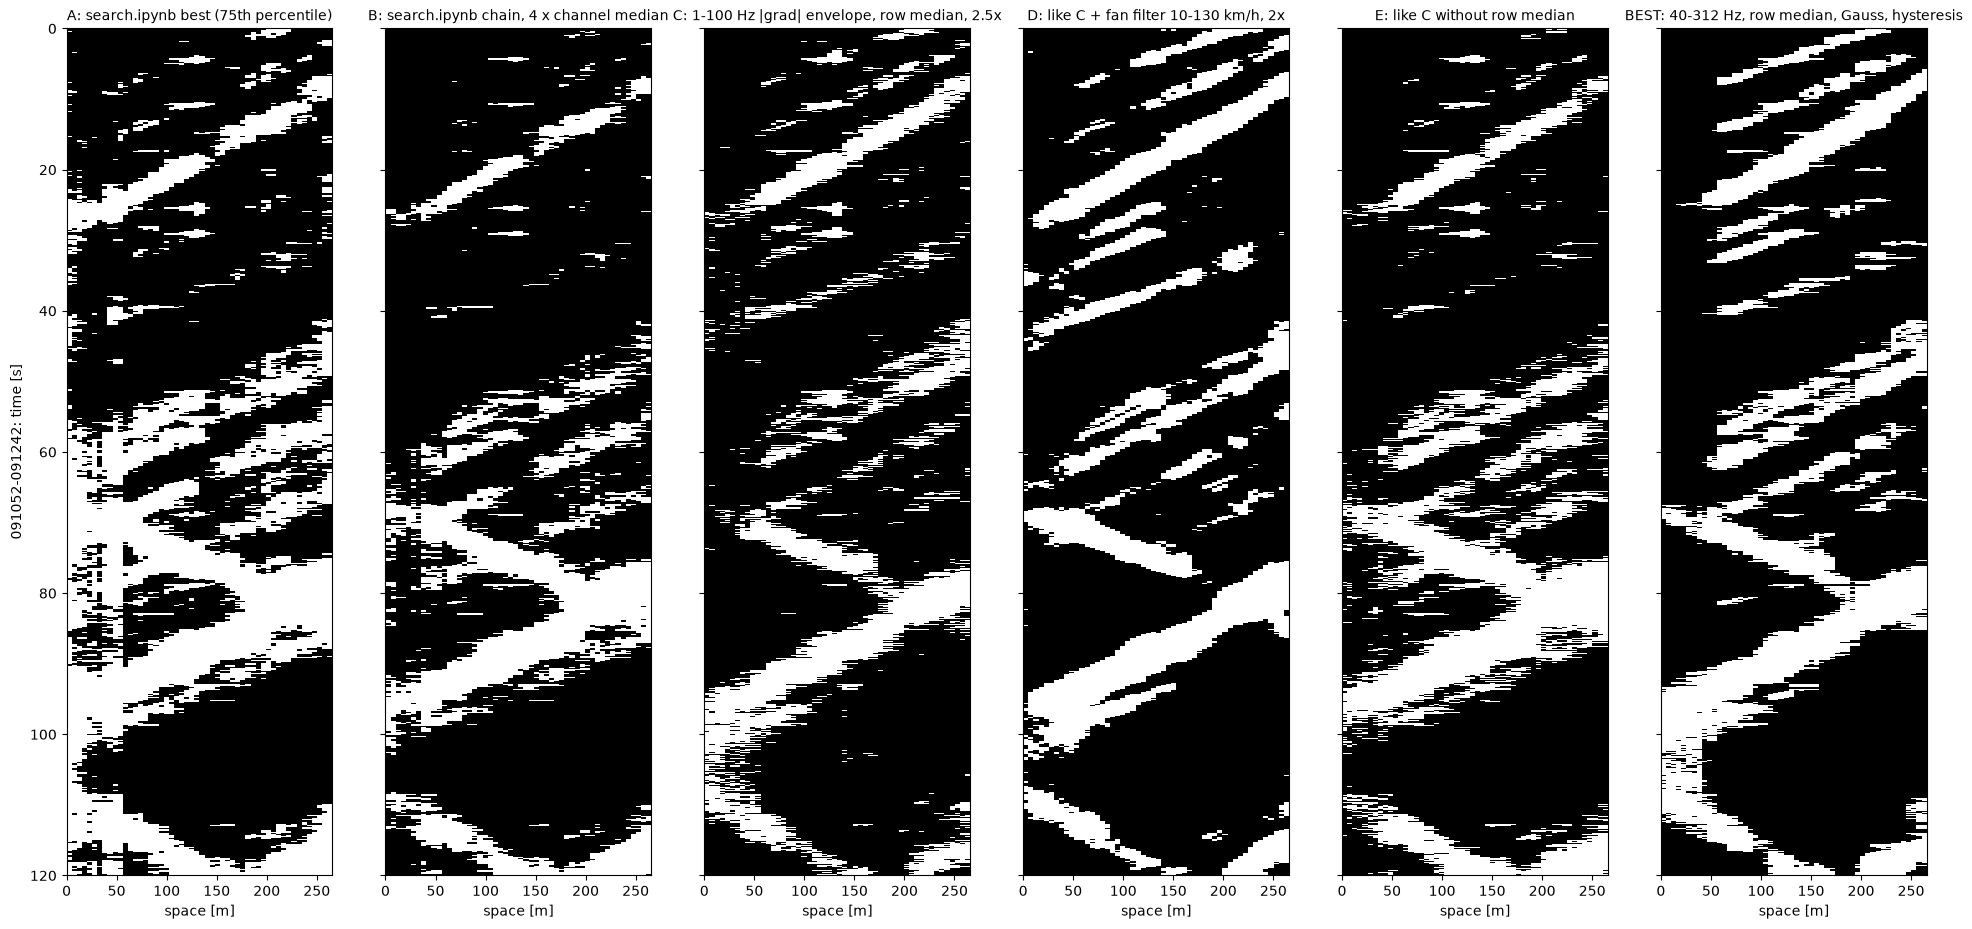

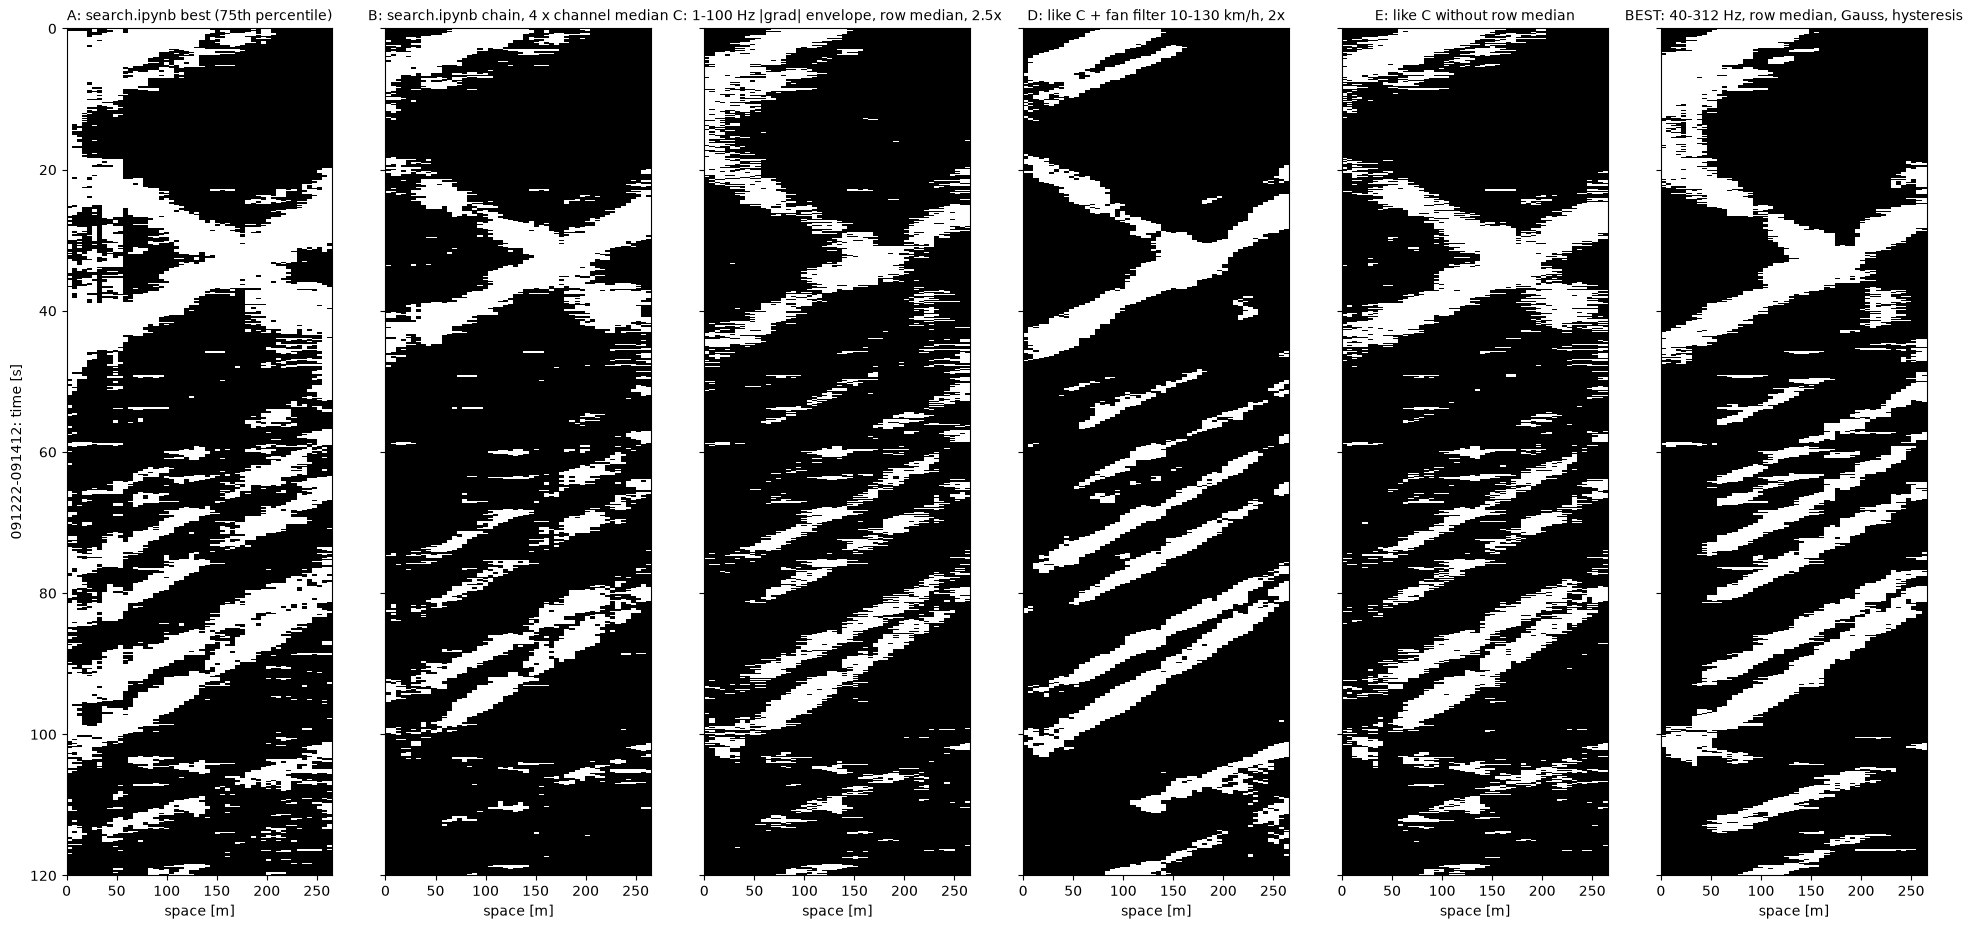

In [8]:
for name in segments:
    fig, axes = plt.subplots(1, len(CANDIDATES), figsize=(4 * len(CANDIDATES), 11), sharey=True)
    for ax, c in zip(axes, CANDIDATES):
        show(ax, masks[(c, name)], c)
    axes[0].set_ylabel(f'{name}: time [s]')
    plt.show()

- **A** floods the image (one third of all pixels), **B** loses faint cars.
- **Removing the row median** (C vs E) removes the horizontal stripes and lowers false alarms.
- **Fan filter** (D) gives smooth, solid lines, but the sharp frequency mask makes "ghost" parallel lines (ringing) and it removes slow/stopping vehicles, so it loses some points.
- **BEST**: thin, continuous lines with almost no speckle; faint cars survive thanks to hysteresis (weak pixels are kept only when they touch a strong part of a line).

## 6. Sensitivity of the chosen chain

How much the result changes when the hysteresis thresholds change (both segments, mean).

In [9]:
rows = []
for lo, hi in [(1.5, 3), (1.75, 3), (1.75, 3.5), (2, 3.5), (2, 4), (2.5, 5)]:
    for name, x in segments.items():
        s = cv2.GaussianBlur(score(x, 40, 312), (1, 5), 0)
        rows.append({'low': lo, 'high': hi, **evaluate(hysteresis(s, np.log(lo), np.log(hi)), reference[name])})
display(pd.DataFrame(rows).groupby(['low', 'high']).mean().round(3))

hit  hit 0.25 s  false  density  speckle
low  high                                            
1.50 3.0   1.000       0.981  0.024    0.286    0.002
1.75 3.0   0.981       0.981  0.016    0.245    0.006
     3.5   0.981       0.981  0.007    0.242    0.003
2.00 3.5   0.933       0.914  0.005    0.211    0.007
     4.0   0.884       0.865  0.002    0.207    0.005
2.50 5.0   0.783       0.768  0.000    0.154    0.007

## 7. Before / after

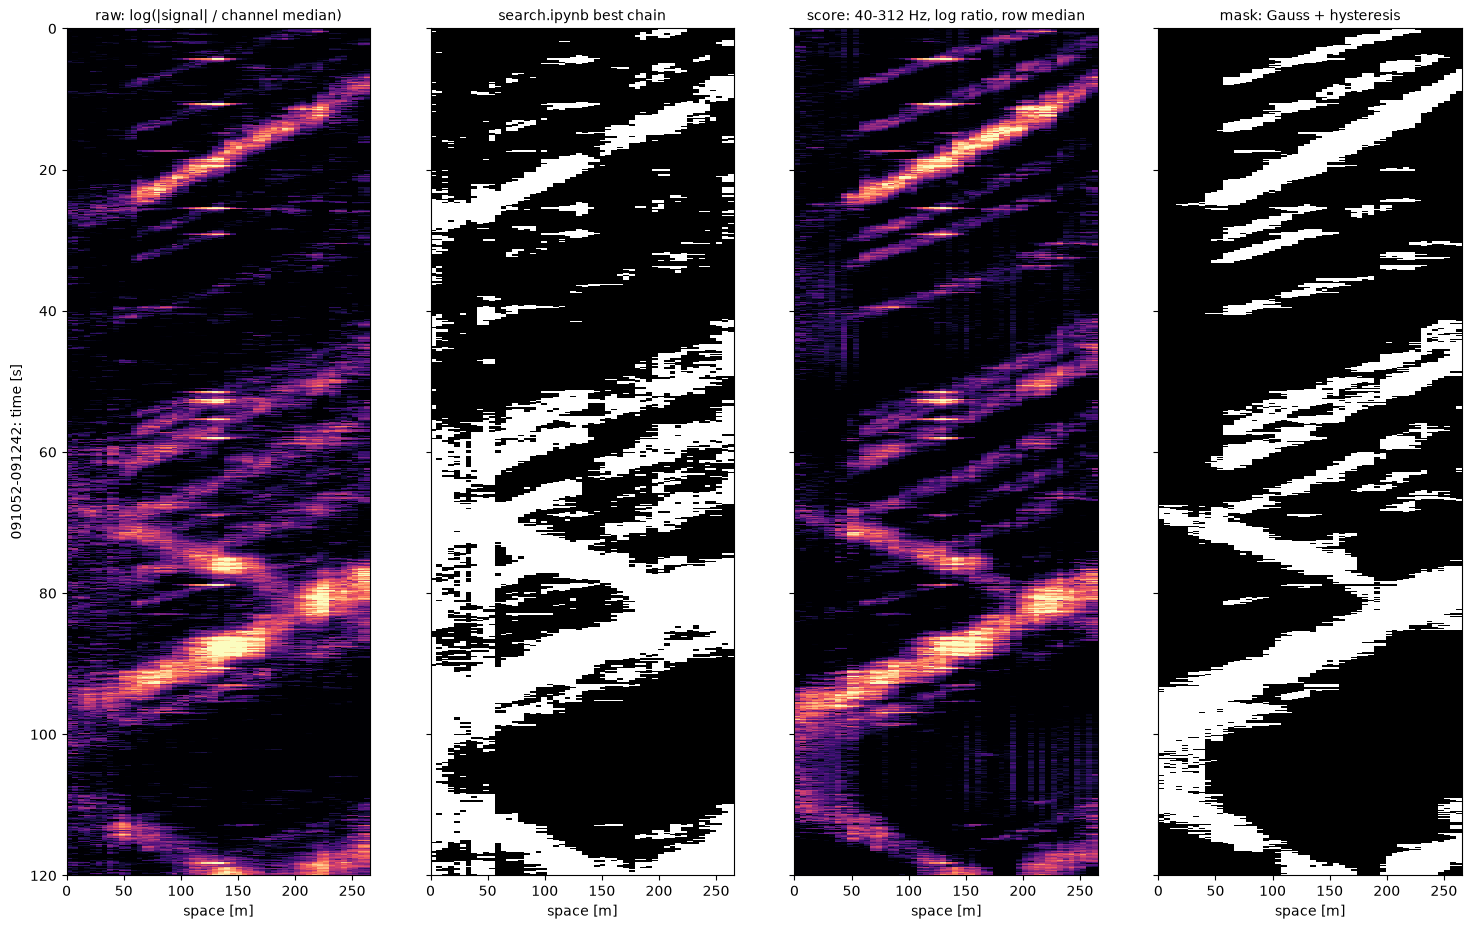

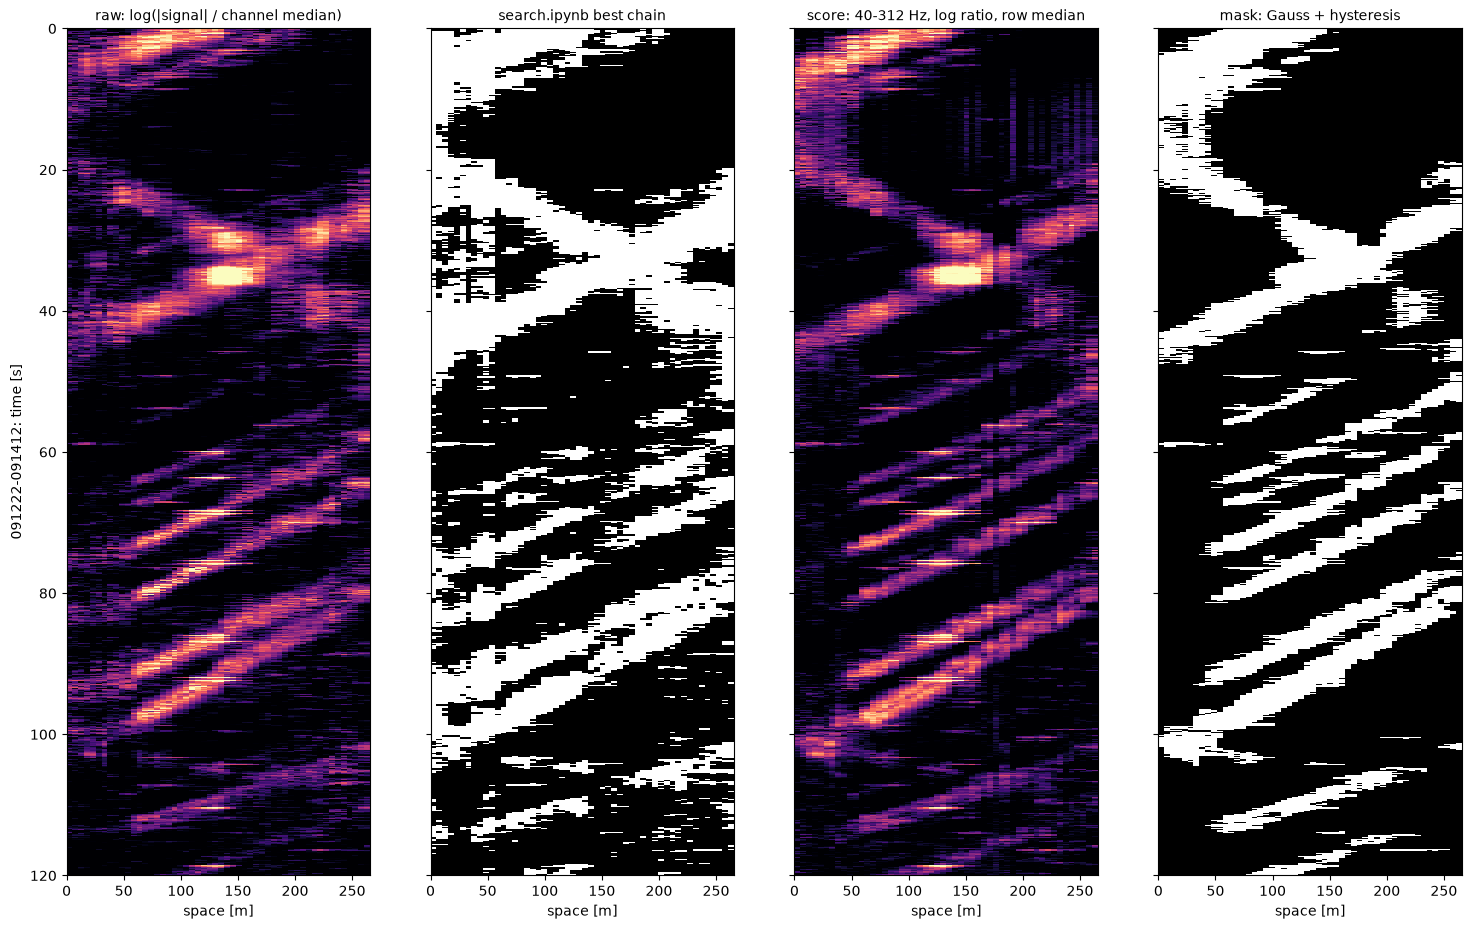

In [10]:
for name, x in segments.items():
    fig, axes = plt.subplots(1, 4, figsize=(18, 11), sharey=True)
    show(axes[0], log_ratio(downsample(np.abs(x))), 'raw: log(|signal| / channel median)')
    show(axes[1], friend_chain(x), 'search.ipynb best chain')
    show(axes[2], score(x, 40, 312), 'score: 40-312 Hz, log ratio, row median')
    show(axes[3], best_chain(x), 'mask: Gauss + hysteresis')
    axes[0].set_ylabel(f'{name}: time [s]')
    plt.show()

## 8. Check on segments not used for tuning

No reference here - only a visual check that the chain works on other traffic.

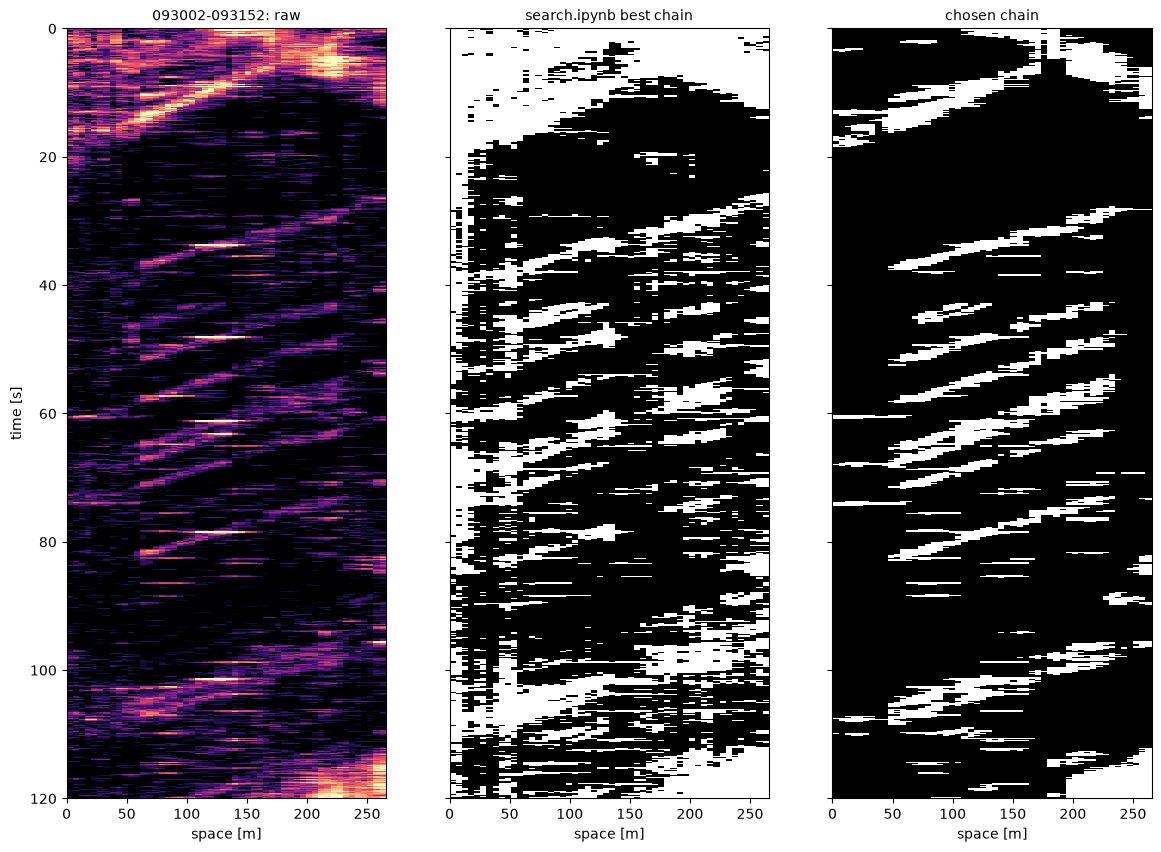

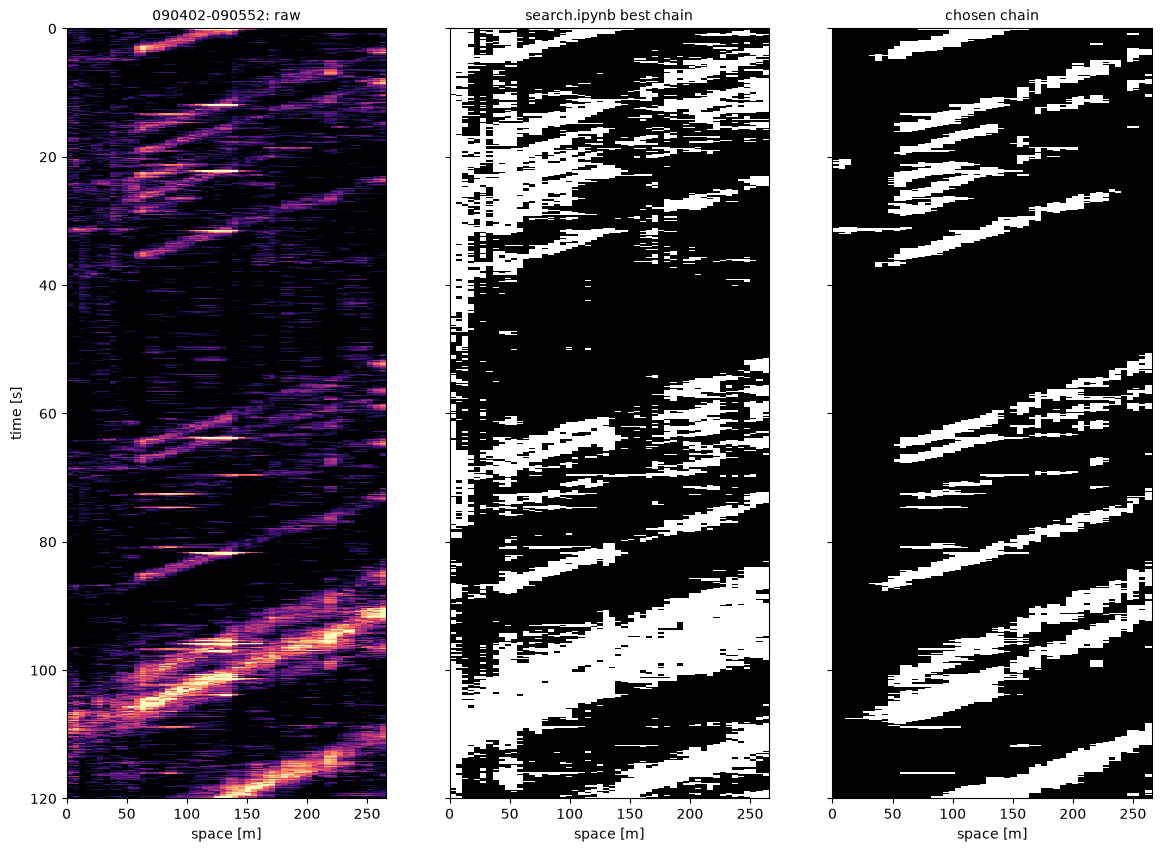

In [11]:
for first, last in [('093002', '093152'), ('090402', '090552')]:
    x = load_real(first, last)
    fig, axes = plt.subplots(1, 3, figsize=(14, 10), sharey=True)
    show(axes[0], log_ratio(downsample(np.abs(x))), f'{first}-{last}: raw')
    show(axes[1], friend_chain(x), 'search.ipynb best chain')
    show(axes[2], best_chain(x), 'chosen chain')
    axes[0].set_ylabel('time [s]')
    plt.show()

## 9. Whole recording (09:00:17 - 09:43:42)

The chosen chain on all 259 files. The files are processed in chunks of 12 (2 min) with 1 extra file on both sides, so the FFT band-pass has no edge effects at the cuts (the extra files are thrown away after processing). One file pair is missing (09:02:37-09:02:47, gray).

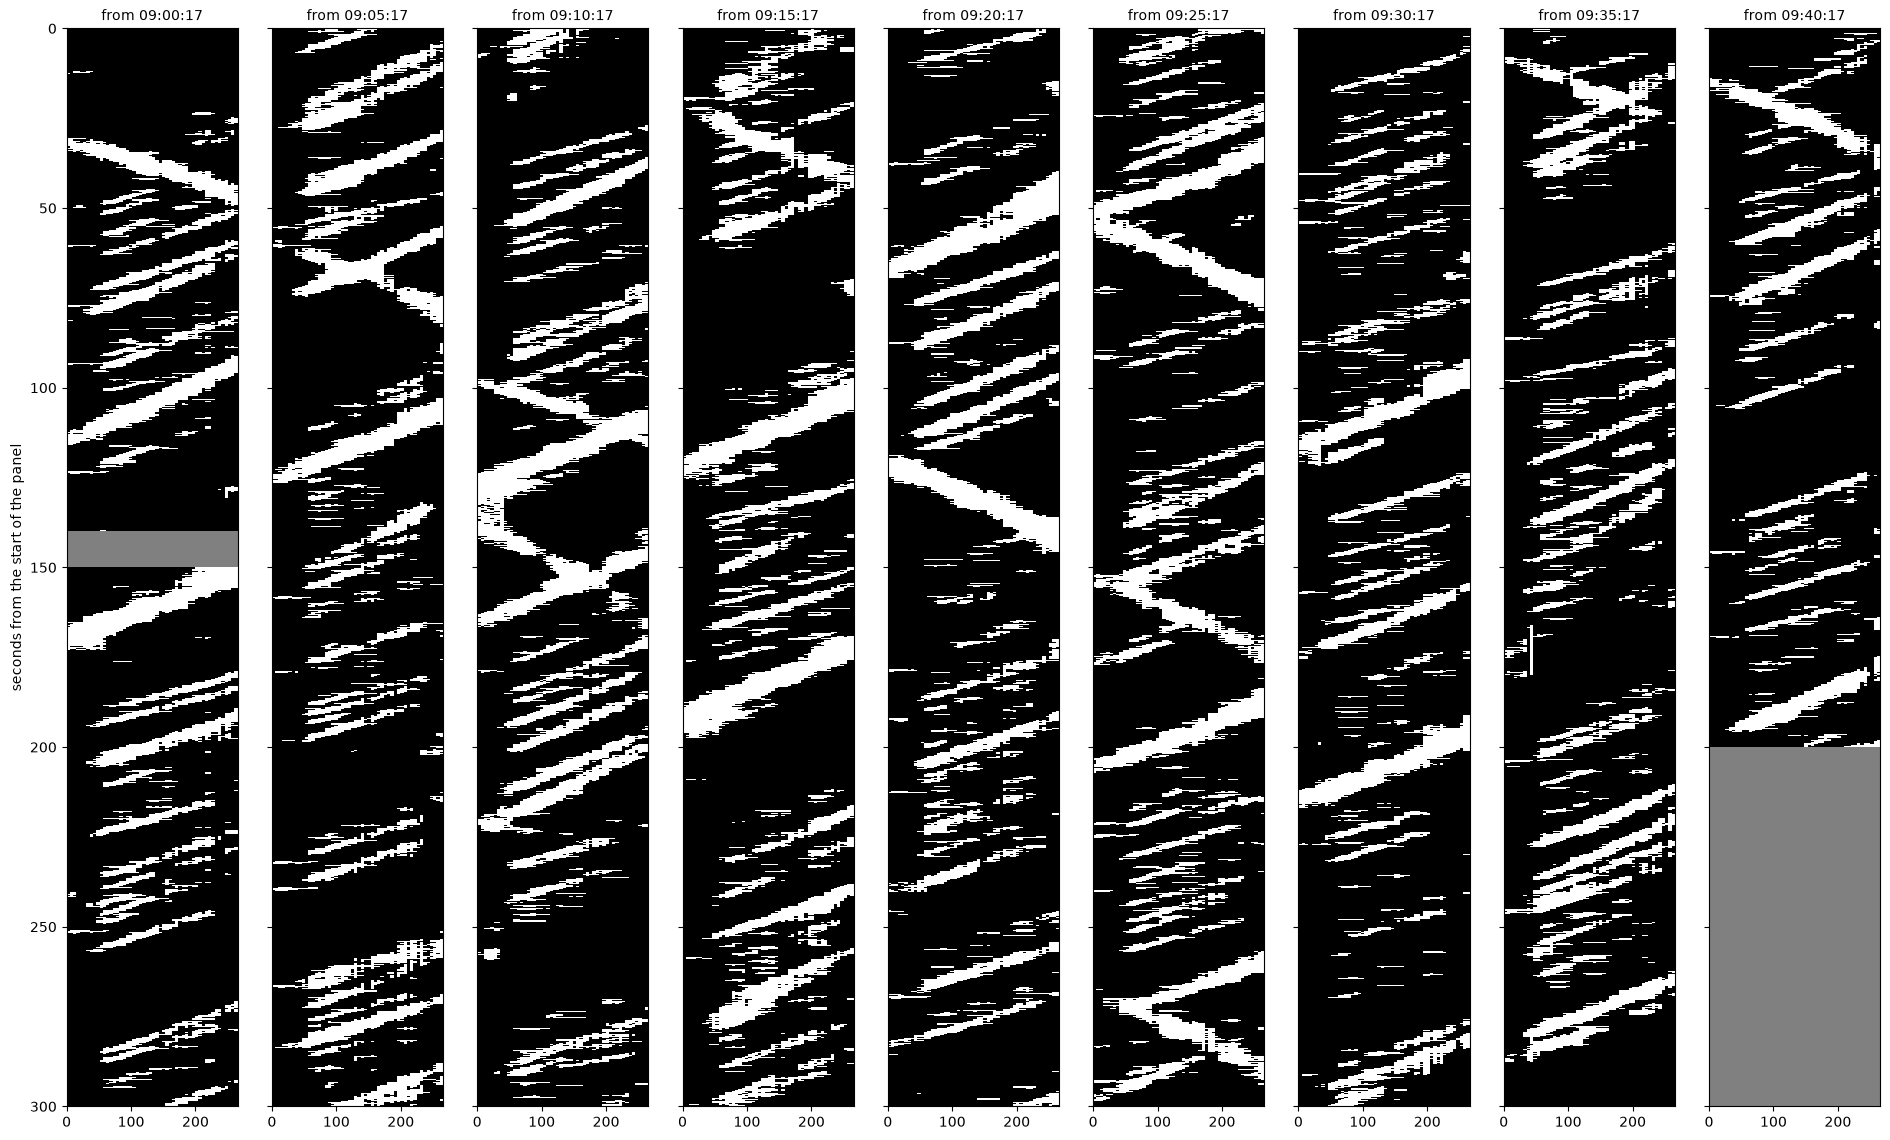

In [12]:
files = sorted(glob.glob('real-world-data/*.npy'))
seconds = np.array([int(f[-10:-8]) * 3600 + int(f[-8:-6]) * 60 + int(f[-6:-4]) for f in files])
ROWS_PER_FILE = 6250 // STEP
slots = (seconds - seconds[0]) // 10                    # place of every file on the time axis (10 s per file)
full_mask = np.full(((slots[-1] + 1) * ROWS_PER_FILE, 52), np.nan)
starts = [0] + [i for i in range(1, len(files)) if seconds[i] - seconds[i - 1] != 10] + [len(files)]
for a, b in zip(starts[:-1], starts[1:]):              # every part without missing files
    for c in range(a, b, 12):
        lo, hi = max(c - 1, a), min(c + 13, b)          # 12 files + 1 file margin on both sides
        x = np.concatenate([np.load(f) for f in files[lo:hi]]).astype(np.float64)
        mask = best_chain(x)
        for j in range(c - lo, min(c + 12, b) - lo):
            r = slots[lo + j] * ROWS_PER_FILE
            full_mask[r:r + ROWS_PER_FILE] = mask[j * ROWS_PER_FILE:(j + 1) * ROWS_PER_FILE]


def clock(s):
    return f'{s // 3600:02d}:{s % 3600 // 60:02d}:{s % 60:02d}'


PANEL = int(300 / DT2)   # 5 minutes per panel
n_panels = int(np.ceil(len(full_mask) / PANEL))
fig, axes = plt.subplots(1, n_panels, figsize=(2.6 * n_panels, 14), sharey=True)
for p, ax in enumerate(axes):
    part = np.nan_to_num(full_mask[p * PANEL:(p + 1) * PANEL], nan=0.5)
    ax.imshow(part, aspect='auto', cmap='gray', vmin=0, vmax=1, interpolation='nearest', extent=[0, 52 * DX, len(part) * DT2, 0])
    ax.set_title(f'from {clock(seconds[0] + p * 300)}', fontsize=10)
    ax.set_ylim(300, 0)
    ax.set_facecolor('gray')   # after the end of the recording
axes[0].set_ylabel('seconds from the start of the panel')
plt.show()

Share of the image in the mask per minute (a rough measure of traffic) and the segments: ours (blue, orange) and the proposed third one (green).

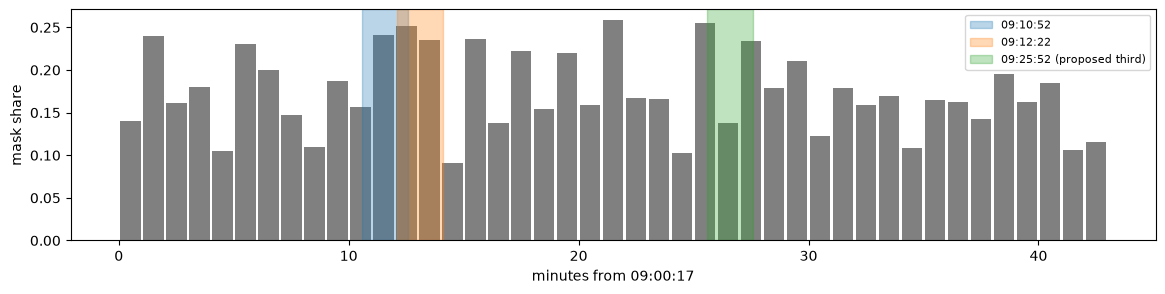

In [13]:
per_minute = np.nanmean(full_mask[:len(full_mask) // 1500 * 1500].reshape(-1, 1500 * 52), axis=1)   # 1500 rows = 60 s
fig, ax = plt.subplots(figsize=(14, 3))
ax.bar(np.arange(len(per_minute)) + 0.5, per_minute, width=0.9, color='gray')
for (first, last), color, label in [(('091052', '091242'), 'tab:blue', '09:10:52'), (('091222', '091412'), 'tab:orange', '09:12:22'),
                                    (('092552', '092742'), 'tab:green', '09:25:52 (proposed third)')]:
    to_min = lambda f: (int(f[:2]) * 3600 + int(f[2:4]) * 60 + int(f[4:]) - seconds[0]) / 60
    ax.axvspan(to_min(first), to_min(last) + 1 / 6, color=color, alpha=0.3, label=label)
ax.set_xlabel(f'minutes from {clock(seconds[0])}')
ax.set_ylabel('mask share')
ax.legend(loc='upper right', fontsize=8)
plt.show()

- The chain behaves the same over the whole recording: 9-26 % of the image per minute, following the traffic (the `search.ipynb` chain marks 33 % everywhere).
- Visible: groups of cars (probably released by traffic lights), thick tram lines every few minutes, both directions, X crossings (e.g. about 09:06:25, 09:12:30, 09:22:20, 09:26:05, 09:40:35).
- Weak spots: very faint cars sometimes become dashed lines; the first ~10 channels are weak everywhere; crossings are one white X (to be split in the detection step).
- **Proposed third segment: 09:25:52-09:27:52** (files 092552-092742) - does not overlap ours, was not used for tuning, has two crossing trams and groups of cars.

## Summary

**Chosen chain** (all steps from Lab 1-4):
1. band-pass **40-312 Hz** per channel (Lab 4 FFT) - where vehicles stand out most from the background (35-40 dB),
2. envelope: |signal| averaged over 0.04 s,
3. log(value / channel median) (Lab 1 point operation) - every channel on the same scale,
4. subtract the **median of every row** - removes bursts that hit all channels at once (horizontal stripes),
5. Gaussian blur 0.2 s along time (Lab 2),
6. **hysteresis threshold** 1.75x / 3.5x: pixels > 3.5x the channel median are seeds, then repeated dilation (Lab 3) inside pixels > 1.75x.

Compared with the `search.ipynb` chain on the reference: false alarms in quiet areas down from ~4.5 % to < 1 %, mask density from 33 % to 24 %, reference points hit 96-100 % (old chain 93-94 %), speckle almost zero, and the lines lie closer to the reference (98 % of points within 0.25 s vs 90 %). On two unseen segments it gives clean, separate lines where the old chain floods the image, and on the whole 43-minute recording it stays stable (9-26 % of the image per minute).

**Limitations:**
- the reference is hand-made (60 points, 9 quiet boxes) - it checks recall and false alarms, not the exact shape of the lines,
- the first ~10 channels (0-50 m) are weak in every band - vehicles often appear only from ~50 m,
- stripes that cover only part of the channels are not removed by the row median,
- stopped vehicles (e.g. trams at the stop at 0-20 m, 09:12:22 + 5-22 s) stay in the mask - they have to be removed in the detection step (speed ~0).